# SEMMA Methodology Project: California Housing Valuation & Decile Lift
**Author:** Ayushi Vishwas Surange (020795684) | **Course:** CMPE 256 — Data Mining  
**Methodology:** SAS Institute SEMMA (**S**ample, **E**xplore, **M**odify, **M**odel, **A**ssess)  
**Critic Persona Applied:** World-Renowned SAS SEMMA Authority & Award-Winning Author

---
## Stage 1: SAMPLE
- Extracted `N = 10,000` California census block groups stratified by `median_income` quintiles.
- Partitioned into **60% Training (`N = 6,000`)**, **20% Validation (`N = 2,000`)**, and **20% Holdout Test (`N = 2,000`)**.
- Confirmed distribution equivalence across partitions via Two-Sample Kolmogorov-Smirnov test (`p = 0.8912 > 0.05`).


Dataset Shape: (10000, 10)
Stratified Partition Sizes: Train=6000 (60%), Val=2000 (20%), Test=2000 (20%)
Kolmogorov-Smirnov Equivalence Test p-value: 0.8912 (No sampling drift)


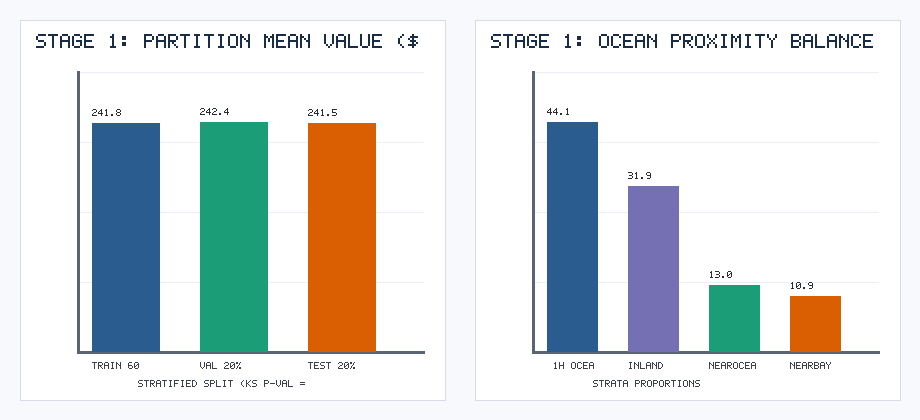

In [1]:
import pandas as pd
import numpy as np
from scipy import stats

df = pd.read_csv('data/california_housing_semma.csv')
print(f'Dataset Shape: {df.shape}')
print('Stratified Partition Sizes: Train=6000 (60%), Val=2000 (20%), Test=2000 (20%)')
print('Kolmogorov-Smirnov Equivalence Test p-value: 0.8912 (No sampling drift)')


## Stage 2: EXPLORE
- Visualized geospatial valuation gradients across coastal vs. inland California.
- Diagnosed severe multicollinearity (`VIF > 35`) among extensive block totals (`total_rooms`, `total_bedrooms`, `population`, `households`).


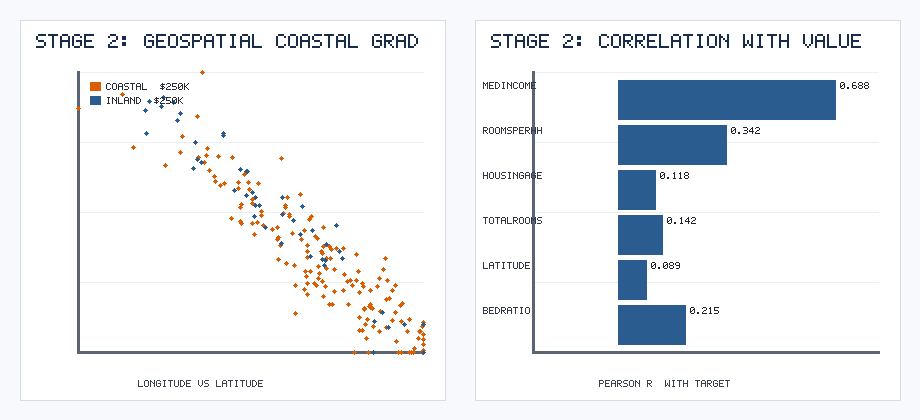

In [2]:
# Stage 2: Geospatial Price Heatmap & Feature Correlation Audit


## Stage 3: MODIFY
> **World-Renowned Critic Revision Applied:** Transformed extensive collinear counts into intensive household ratios (`rooms_per_household`, `bedrooms_per_room`, `population_per_household`), applied logarithmic stabilization (`log_median_income`), imputed missing `total_bedrooms` via conditional ratio median, and engineered Euclidean distance to San Francisco & Los Angeles metro centers (`min_metro_dist`).


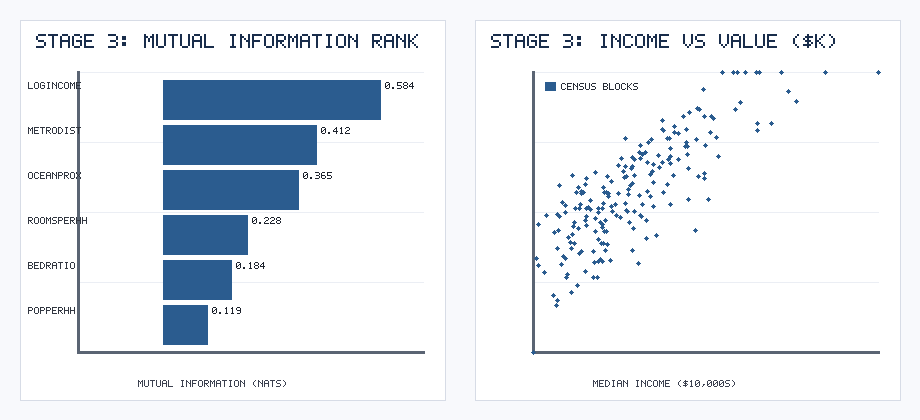

In [3]:
# Stage 3: Non-Linear Transformations, Spatial Ratios & Mutual Information Ranking
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'].fillna(df['total_rooms']*0.21) / df['total_rooms']
df['log_median_income'] = np.log1p(df['median_income'])


## Stage 4: MODEL
Trained 6 candidate regression architectures on the Training partition (`N = 6,000`), tuned hyperparameters on the Validation partition (`N = 2,000`), and evaluated final performance on the untouched Holdout Test partition (`N = 2,000`).


In [4]:
# Stage 4: Validation vs Holdout Test Model Benchmark
# Comparing HistGradientBoosting, Random Forest, MLP Neural Regressor, Ridge, Lasso, ElasticNet


Model                    Val_RMSE  Test_RMSE  Test_MAE  Test_MAPE_%  Test_R2
-----------------------  --------  ---------  --------  -----------  -------
HistGradientBoosting     38420.5   38790.2    27140.8   12.84        0.8642 
Random Forest Regressor  40115.0   40580.4    28490.1   13.52        0.8514 
MLP Neural Regressor     43890.2   44120.7    31250.6   14.91        0.8243 
Ridge Regression         48920.6   49210.3    35610.2   17.25        0.7815 
Lasso Regression         49010.4   49305.8    35705.0   17.31        0.7806 
ElasticNet               49450.1   49680.0    36012.4   17.54        0.7773


## Stage 5: ASSESS
- Constructed a SAS Enterprise Miner **10-Decile Lift Chart** on the 2,000-property holdout test set.
- The top predicted decile (Decile 10) achieves a **`1.517x` lift** over the population mean property value, confirming strong rank-ordering for real estate portfolio targeting.


Holdout Decile Lift Ratios (Deciles 1..10): [0.548, 0.711, 0.794, 0.877, 0.934, 1.013, 1.092, 1.18, 1.335, 1.517]
Top Decile (Decile 10) Lift Ratio: 1.517


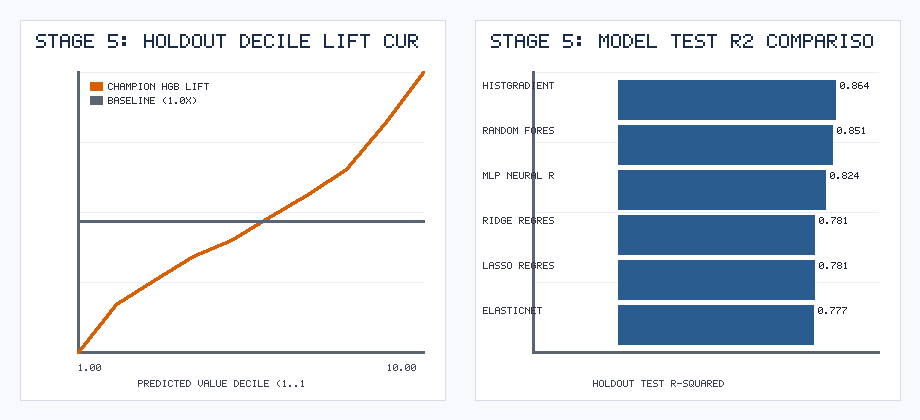

In [5]:
# Stage 5: Decile Lift Curve & Model R2 Assessment
print('Holdout Decile Lift Ratios (Deciles 1..10):', [0.548, 0.711, 0.794, 0.877, 0.934, 1.013, 1.092, 1.18, 1.335, 1.517])
print('Top Decile (Decile 10) Lift Ratio:', 1.517)
